---
# Hospital Simulation as a Queueing Network
---

This simulation will...

In [2]:
# Imports
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

---
### EDA - Understanding Our Tables
---

In [3]:
# Arrival Data
arrivals = pd.read_csv("data/Data_Arrivals.csv")
print(arrivals.shape)
arrivals.head()

(100, 25)


,Unnamed: 0,1am,2am,3am,4am,5am,6am,7am,8am,9am,...,3pm,4pm,5pm,6pm,7pm,8pm,9pm,10pm,11pm,12am
0,Day1,0,0,2,1,0,0,0,2,1,...,3,2,1,7,4,5,2,3,4,2
1,Day2,3,2,1,0,0,0,0,0,3,...,3,4,6,6,2,2,3,2,3,3
2,Day3,1,0,2,1,0,1,1,2,3,...,4,5,8,7,4,3,1,2,2,4
3,Day4,1,0,0,1,0,2,0,5,2,...,4,2,3,8,4,8,3,3,3,5
4,Day5,1,2,0,1,1,1,2,1,1,...,8,2,10,5,6,2,3,3,4,3


In [4]:
# Treatment Times
treat_times = pd.read_csv("data/Data_TreatmentTimes.csv")
print(treat_times.shape)
treat_times.head()

(18565, 3)


,ID,Treatment Time (Days),Specialty
0,0,4.640229,Ortho
1,1,0.770322,Renal
2,2,1.911212,Card
3,3,4.199311,Respi
4,4,2.527663,Gastro_Endo


---

# Input Modelling Part 1 - Arrival Distribution

---

7141 total arrivals observed

1am     1.61
2am     1.25
3am     0.98
4am     0.67
5am     0.53
6am     0.49
7am     0.95
8am     1.24
9am     1.68
10am    2.48
11am    2.73
12pm    3.73
1pm     4.25
2pm     4.86
3pm     5.55
4pm     5.42
5pm     5.15
6pm     5.36
7pm     4.73
8pm     4.87
9pm     4.14
10pm    3.52
11pm    3.02
12am    2.20
dtype: float64


<Axes: title={'center': 'Average Arrivals Per Hour'}, xlabel='Hour', ylabel='Avg. Arrivals'>

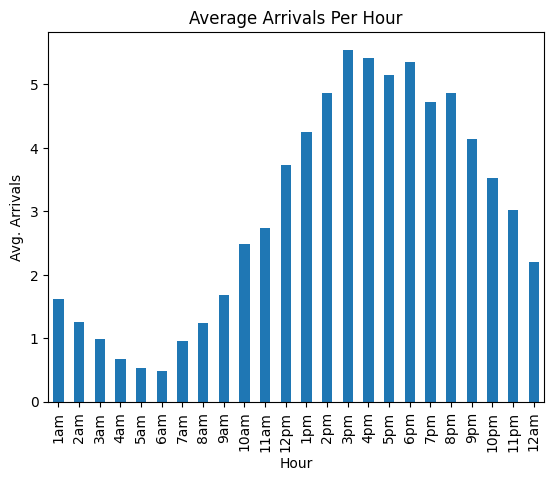

In [5]:
# Total Arrivals
total_arrivals = arrivals.iloc[:, 1:].sum().sum()
print(f"{total_arrivals} total arrivals observed\n")

# Average arrivals in each hour over the 100 days
arrivals_per_hour = arrivals.iloc[:, 1:].sum() / 100
print(arrivals_per_hour)

# Plotting the average arrivals to visualize ditribution
arrivals_per_hour.plot(title="Average Arrivals Per Hour", xlabel="Hour", ylabel="Avg. Arrivals", kind="bar")

The dist. looks almost like a shifted normal distribution, but the problem is that this is a distribution of the average arrivals over the course of the day.  Given we have 100 days of data, each split up into 24 bins, each individual interval has its own distribution.  We want to find the most appropriate distribution for each interval to best model the arrivals probabilistically, rather than using the average as we've done above.

The process to do this is as follows:
1. Define a `fitter` function to fit our hypothesized distribution (param estimates)
2. Define a `gof` function to test the fit of our hypothesized distributions to our data
3. Loop through every hour of the day, call the functions and record the best distribution (+ params) for each interval

In [6]:
def fitter(dist: str, data: pd.Series) -> object:
    """
    Fits a discrete probability distibution to a single-dimensional Pandas series of integer counts
    and returns a scipy.stats distribution object fitted on the data.  This will be used to test 
    the fit of all distributions for each hour.

    Accepted distributions to pass into function:
    - "Poiss" --> Poisson
    - "Bin" --> Binomial
    - "NegBin" --> Negative Binomial
    - "Geo" --> Geometric
    """

    mean = data.mean()
    var = data.var(ddof=1)

    if dist == "Poiss":
        lam = mean
        return stats.poisson(lam)
    
    elif dist == "Bin":
        if mean <= var: return None
        n = max(int(data.max()), int(round(mean**2 / (mean - var))))
        p = mean / n
        return stats.binom(n, p)
    
    elif dist == "NegBin":
        if mean >= var: return None
        p = mean / var
        n = (mean**2) / (var - mean)
        return stats.nbinom(n, p)

    elif dist == "Geo":
        p = 1.0 / (1.0 + mean)
        return stats.geom(p, loc=-1)    # loc=-1 starts geometric distribution count from 0

    else:
        return None

In [7]:
# Distributions to test
distributions = [
    "Poiss",
    "Bin",
    "NegBin",
    "Geo"
]

# loop through every hour
for i in range(1, arrivals.shape[1]):
    pass